# Deep Hedging for a Two-Asset Product Option

A neural-network hedging strategy for a European call on the normalized product of two correlated assets.

## Problem setup

- Two tradable assets $S^1$ and $S^2$ follow correlated geometric Brownian motions.
- **Payoff:** $g(S_T^1,S_T^2)=\left(\frac{S_T^1 S_T^2}{S_0^1 S_0^2}-1\right)^+$.
- **Hedge:** two time-varying positions $\delta_t^1$ and $\delta_t^2$, one in each asset.
- **Portfolio:** self-financing discrete-time rebalancing with interest rate $r$.

The model learns both the hedge and the initial premium by minimizing the mean squared terminal hedging error.

In [1]:
import numpy as np
import tensorflow as tf

import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import keras

from keras.layers import Subtract, Multiply, Lambda, Add, Concatenate
from keras import initializers

import matplotlib.pyplot as plt

## 1. Parameters

In [2]:
# Model parameters
N = 100          # number of time steps
T = 1.0          # maturity (1 year)
S0_1 = 1.0       # initial price of asset 1
S0_2 = 1.0       # initial price of asset 2

mu1 = 0.025      # drift of asset 1
mu2 = -0.01      # drift of asset 2
sigma1 = 0.22    # volatility of asset 1
sigma2 = 0.3     # volatility of asset 2
rho = 0.5        # correlation between the two Brownian increments
r = 0.04         # interest rate

# Time grid
grid = [i * T / N for i in range(N + 1)]
Delta_T = [grid[i+1] - grid[i] for i in range(N)]
dt = T / N

## 2. Generate the Training Set

We simulate $N_{\text{train}}$ two-dimensional trajectories $(S^{1,i}_{t_j}, S^{2,i}_{t_j})$ under the log-normal model:

$$
\log S^1_{t_{j+1}} = \log S^1_{t_j} + \mu_1 \Delta t + \sigma_1 \sqrt{\Delta t}\, G^1_j
$$
$$
\log S^2_{t_{j+1}} = \log S^2_{t_j} + \mu_2 \Delta t + \sigma_2 \sqrt{\Delta t}\, G^2_j
$$

where $(G^1_j, G^2_j) \sim \mathcal{N}(\mathbf{0}, C)$ with $C = \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}$.

In [3]:
N_train = 10**5

# Covariance matrix for the correlated Gaussians
cov_matrix = np.array([[1.0, rho],
                        [rho, 1.0]])

def generate_log_increments(N_samples, seed=None):
    """Generate correlated log-increments for both assets.
    """
    if seed is not None:
        np.random.seed(seed)

    log_incr1 = []
    log_incr2 = []
    for j in range(N):
        dt_j = Delta_T[j]
        G = np.random.multivariate_normal(mean=[0, 0], cov=cov_matrix, size=N_samples)  # (N_samples, 2)
        G1 = G[:, 0]
        G2 = G[:, 1]

        # Log-increments: mu_k * dt + sigma_k * sqrt(dt) * G_k
        linc1 = mu1 * dt_j + sigma1 * np.sqrt(dt_j) * G1
        linc2 = mu2 * dt_j + sigma2 * np.sqrt(dt_j) * G2

        log_incr1.append(linc1.reshape(-1, 1))
        log_incr2.append(linc2.reshape(-1, 1))

    return log_incr1, log_incr2

log_incr1_train, log_incr2_train = generate_log_increments(N_train, seed=42)

print(f"Training set size: {N_train}")
print(f"Shape of each log-increment array: {log_incr1_train[0].shape}")

Training set size: 100000
Shape of each log-increment array: (100000, 1)


### Plot sample trajectories

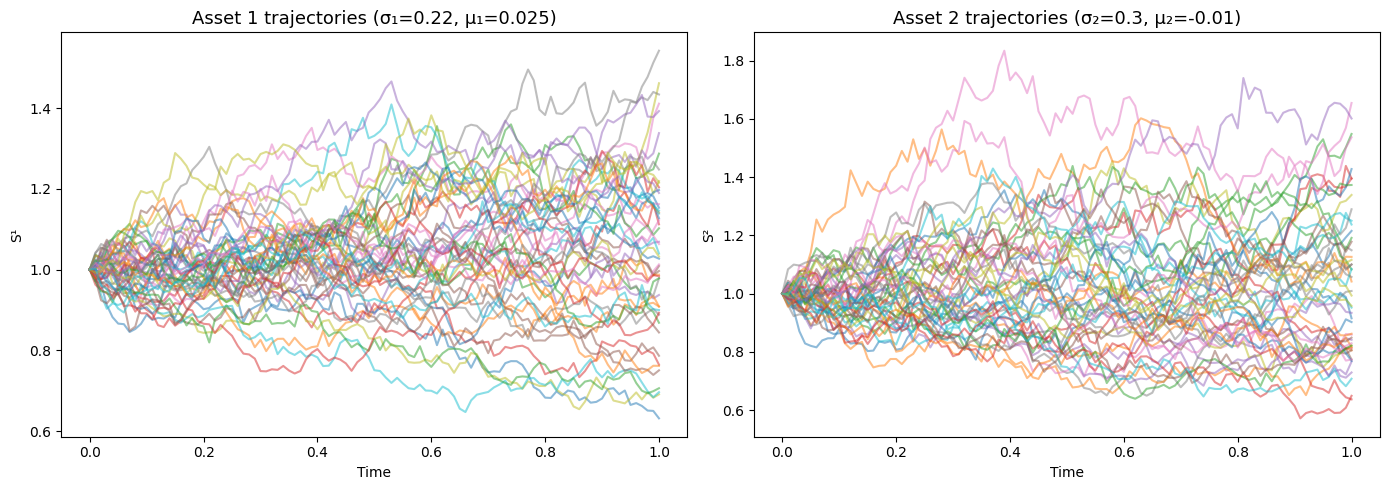

In [4]:
M = 50  # number of trajectories to plot

# price paths from log-increments, column of zeros so cumsum starts at log(S0) = 0
log_inc1_plot = np.array([li[:M, 0] for li in log_incr1_train])  # (N, M)
log_inc2_plot = np.array([li[:M, 0] for li in log_incr2_train])

log_inc1_with_start = np.vstack([np.zeros((1, M)), log_inc1_plot])
log_inc2_with_start = np.vstack([np.zeros((1, M)), log_inc2_plot])

traj1 = S0_1 * np.exp(np.cumsum(log_inc1_with_start, axis=0))
traj2 = S0_2 * np.exp(np.cumsum(log_inc2_with_start, axis=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(grid, traj1, alpha=0.5)
axes[0].set_title(f"Asset 1 trajectories (σ₁={sigma1}, μ₁={mu1})", fontsize=13)
axes[0].set_xlabel("Time")
axes[0].set_ylabel("S¹")

axes[1].plot(grid, traj2, alpha=0.5)
axes[1].set_title(f"Asset 2 trajectories (σ₂={sigma2}, μ₂={mu2})", fontsize=13)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("S²")

plt.tight_layout()
plt.show()

## 3. Build the Deep Hedging Model

### Architecture

At each time step $t_j$, we use a **single shared neural network** $h: \mathbb{R}^3 \to \mathbb{R}^2$ that takes $(t_j, S^1_{t_j}, S^2_{t_j})$ as input and outputs $(\delta^1_{t_j}, \delta^2_{t_j})$. The same network $h$ is reused at every time step, as time $t_j$ is an explicit input instead of the more naive approach of one network for each step.

The option premium $\pi_\theta(S^1_0, S^2_0)$ is parameterized by a separate small network. Since $S^1_0 = S^2_0 = 1$ are constant across all training paths, $\pi_\theta$ effectively learns a single scalar — the initial portfolio value $V_0$.

### Portfolio evolution (with $r \neq 0$)

$$
V_{t_{j+1}} = V_{t_j} + r\left(V_{t_j} - \sum_{k=1}^2 \delta^k_{t_j} S^k_{t_j}\right)\Delta t + \sum_{k=1}^2 \delta^k_{t_j}(S^k_{t_{j+1}} - S^k_{t_j})
$$

In [5]:
# Neural network architecture
m_in = 3  # input dimension: (t,S1, S2)
m_out = 2  # output dimension: (delta1, delta2)
d = 3      # number of layers (including output)
n = 64     # hidden units per layer

# Build NN of depth d
layers = []
for k in range(d):
    if k < d - 1:
        layer = keras.layers.Dense(
            units=n, activation='tanh', trainable=True, #tanh used for deep hedging
            kernel_initializer='glorot_normal', #better for tanh
            bias_initializer='zeros',
            name=f'h{k}'
        )
    else:
        layer = keras.layers.Dense(
            units=m_out, activation='linear', trainable=True,
            name=f'output_{k}'
        )
    layers.append(layer)

print(f"Shared NN layers created: {len(layers)}")

Shared NN layers created: 3


In [6]:
# Build the Keras computational graph

price1_in = keras.Input(shape=(1,), name='price1_in')
price2_in = keras.Input(shape=(1,), name='price2_in')

inputs = [price1_in, price2_in]

# --- Premium network: pi_theta(S1_0, S2_0) ---
premium_input_concat = Concatenate(name='premium_concat')([price1_in, price2_in])
premium = keras.layers.Dense(units=32, activation='tanh', trainable=True,
                             kernel_initializer=initializers.RandomNormal(0, 0.1),
                             bias_initializer=initializers.RandomNormal(0, 0.1),
                             name='premium_hidden')(premium_input_concat)
premium = keras.layers.Dense(units=1, activation='linear', trainable=True,
                             kernel_initializer=initializers.RandomNormal(0, 0.1),
                             bias_initializer=initializers.RandomNormal(0, 0.1),
                             name='premium_out')(premium)

# Initialize portfolio value V_0 = pi_0
portfolio_value = premium

current_price1 = price1_in
current_price2 = price2_in

# Lists to store delta outputs for visualization
delta1_outputs = []
delta2_outputs = []

# --- Loop over time steps ---
for j in range(N):

    t_in = keras.Input(shape=(1,), name=f'time_t{j}')
    inputs.append(t_in)

    # Concatenate (t, S1, S2)
    price_concat = Concatenate(name=f'price_cat_t{j}')([
        t_in, current_price1, current_price2
    ])

    # Pass through SHARED NN
    strategy = price_concat
    for k in range(d):
        strategy = layers[k](strategy)

    # Split delta1 and delta2
    delta1 = Lambda(lambda x: x[:, 0:1], name=f'delta1_t{j}')(strategy)
    delta2 = Lambda(lambda x: x[:, 1:2], name=f'delta2_t{j}')(strategy)

    delta1_outputs.append(delta1)
    delta2_outputs.append(delta2)

    # Log-increment inputs
    incr1 = keras.Input(shape=(1,), name=f'logincr1_t{j}')
    incr2 = keras.Input(shape=(1,), name=f'logincr2_t{j}')
    inputs.extend([incr1, incr2])

    # Price updates: S_{j+1} = S_j * exp(log_increment)
    logprice1 = Lambda(lambda x: tf.math.log(x))(current_price1)
    logprice1 = Add()([logprice1, incr1])
    pricenew1 = Lambda(lambda x: tf.math.exp(x))(logprice1)

    logprice2 = Lambda(lambda x: tf.math.log(x))(current_price2)
    logprice2 = Add()([logprice2, incr2])
    pricenew2 = Lambda(lambda x: tf.math.exp(x))(logprice2)

    # Price increments
    priceincr1 = Subtract()([pricenew1, current_price1])
    priceincr2 = Subtract()([pricenew2, current_price2])

    # Portfolio evolution
    dt_j = Delta_T[j]

    delta1_times_S1 = Multiply()([delta1, current_price1])
    delta2_times_S2 = Multiply()([delta2, current_price2])

    # Cash = V - delta*S
    cash_part = Subtract()([portfolio_value, delta1_times_S1])
    cash_part = Subtract()([cash_part, delta2_times_S2])

    # Interest
    interest = Lambda(lambda x, c=r * dt_j: x * c)(cash_part)

    # Hedge gains
    hedge_gain1 = Multiply()([delta1, priceincr1])
    hedge_gain2 = Multiply()([delta2, priceincr2])

    # Update portfolio
    portfolio_value = Add()([portfolio_value, interest])
    portfolio_value = Add()([portfolio_value, hedge_gain1])
    portfolio_value = Add()([portfolio_value, hedge_gain2])

    # Update prices
    current_price1 = pricenew1
    current_price2 = pricenew2

product_ST = Multiply()([current_price1, current_price2])
payoff = Lambda(lambda x: tf.math.maximum(x / (S0_1 * S0_2) - 1.0, 0.0),
                name='payoff')(product_ST)

hedging_error_out = Subtract(name='hedging_error')([portfolio_value, payoff])

outputs = Concatenate(name='final_output')([hedging_error_out, premium])

model = keras.models.Model(inputs=inputs, outputs=outputs)

print(f"Model built. Total parameters: {model.count_params():,}")

Model built. Total parameters: 4,675


In [7]:
# Custom loss: mean squared hedging error
def custom_loss(y_true, y_pred):
    z = y_pred[:, 0] - y_true[:, 0]
    return tf.math.reduce_mean(tf.square(z))

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=custom_loss)
print("Model compiled.")

Model compiled.


## 4. Prepare Training Data and Train

In [8]:
# Build the training input list
# Inputs: [S1_0, S2_0, t0, incr1_t0, incr2_t0, t1, incr1_t1, incr2_t1, ...]

xtrain = [
    S0_1 * np.ones((N_train, 1)),   # price1_in
    S0_2 * np.ones((N_train, 1)),   # price2_in
]

for j in range(N):
    t_val = (grid[j] / T) * np.ones((N_train, 1))
    xtrain.append(t_val)
    xtrain.append(log_incr1_train[j])
    xtrain.append(log_incr2_train[j])

# Target
ytrain = np.zeros((N_train, 1))

print(f"Number of input arrays: {len(xtrain)}")

Number of input arrays: 302


In [9]:
# Train the model
print("Training the deep hedging model...")
history = model.fit(
    x=xtrain,
    y=ytrain,
    epochs=20,
    batch_size=100,
    verbose=True
)

Training the deep hedging model...
Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - loss: 0.0055
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - loss: 0.0022
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 46s 32ms/step - loss: 0.0019
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 36s 27ms/step - loss: 0.0018
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 48s 47ms/step - loss: 0.0015
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 62s 28ms/step - loss: 0.0013
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 42s 29ms/step - loss: 0.0011
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 28s 27ms/step - loss: 8.8162e-04
Epoch 9/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 7.8559e-04
Epoch 10/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 28s 27ms/step - loss: 7.1990e-04
Epoch 11/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - loss: 6.7246e-04
Epoch 12/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 28s 27ms/step - loss: 6.2821e-04
Epoch 13/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 5.8262e-04
Epoch 14/20
10

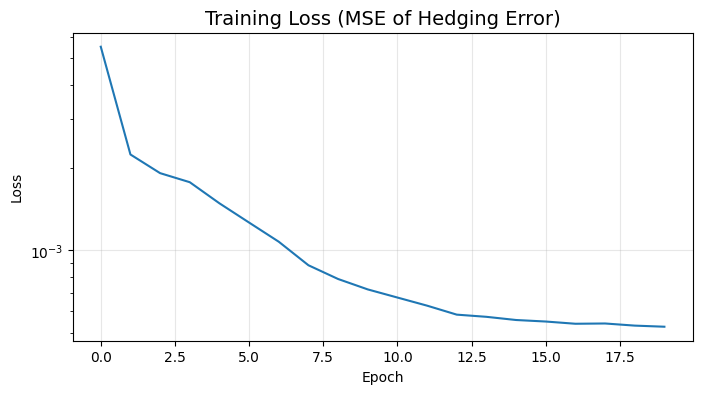

In [10]:
# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'])
plt.title('Training Loss (MSE of Hedging Error)', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

## 5. Assess performance

We evaluate the terminal hedging error

$$
\varepsilon = V_T - \left(\frac{S_T^1 S_T^2}{S_0^1 S_0^2}-1\right)^+.
$$

We compare in-sample and independently simulated out-of-sample errors, inspect the learned hedge ratios, and benchmark the learned premium against risk-neutral Monte Carlo pricing.

In [11]:
# Predict on training set
model_output = model.predict(xtrain)

hedging_error = model_output[:, 0]
learned_premium = np.mean(model_output[:, 1])

print(f"Learned option premium: {learned_premium:.4f}")
print(f"\nHedging error statistics (training set):")
print(f"  Mean:    {np.mean(hedging_error):.4e}")
print(f"  Std dev: {np.std(hedging_error):.4e}")
print(f"  MSE:     {np.mean(hedging_error**2):.4e}")
print(f"  5th pct: {np.percentile(hedging_error, 5):.4e}")
print(f"  95th pct:{np.percentile(hedging_error, 95):.4e}")

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 76s 22ms/step
Learned option premium: 0.2439

Hedging error statistics (training set):
  Mean:    -1.4096e-03
  Std dev: 2.2436e-02
  MSE:     5.0537e-04
  5th pct: -3.9980e-02
  95th pct:3.3321e-02


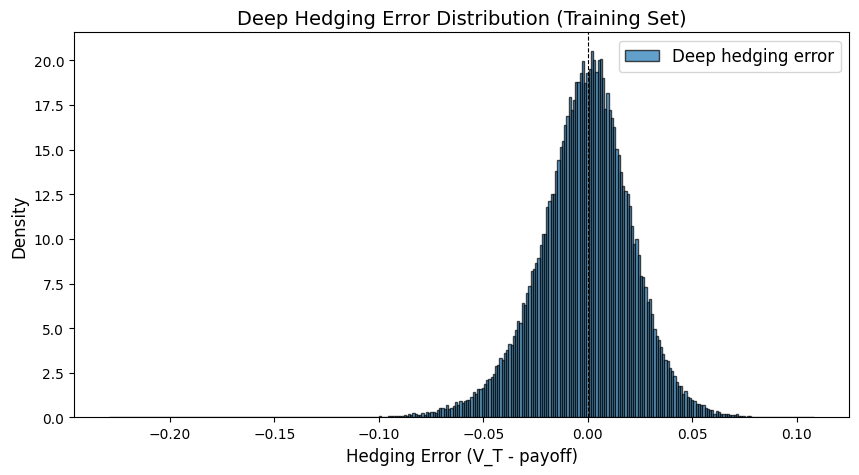

In [12]:
# Histogram of hedging error
plt.figure(figsize=(10, 5))
plt.hist(hedging_error, bins=int(np.sqrt(N_train)), density=True, alpha=0.7,
         edgecolor='black', label='Deep hedging error')
plt.axvline(0, color='k', linestyle='--', linewidth=0.8)
plt.xlabel('Hedging Error (V_T - payoff)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Deep Hedging Error Distribution (Training Set)', fontsize=14)
plt.legend(fontsize=12)
plt.show()

### Interpretation of results

The in-sample hedging error is concentrated near zero, with a small residual bias and dispersion associated with discrete rebalancing and neural-network approximation.

### 5.2 Test set evaluation

In [13]:
# Generate a fresh test set
N_test = 10**4

log_incr1_test, log_incr2_test = generate_log_increments(N_test, seed=123)

xtest = [
    S0_1 * np.ones((N_test, 1)),   # price1_in
    S0_2 * np.ones((N_test, 1))    # price2_in
]

for j in range(N):
    t_val = (grid[j] / T) * np.ones((N_test, 1))
    xtest.append(t_val)
    xtest.append(log_incr1_test[j])
    xtest.append(log_incr2_test[j])

# Model prediction
model_output_test = model.predict(xtest)
hedging_error_test = model_output_test[:, 0]

print(f"\nHedging error statistics (test set, N_test={N_test}):")
print(f"  Mean:    {np.mean(hedging_error_test):.4e}")
print(f"  Std dev: {np.std(hedging_error_test):.4e}")
print(f"  MSE:     {np.mean(hedging_error_test**2):.4e}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step

Hedging error statistics (test set, N_test=10000):
  Mean:    -1.2580e-03
  Std dev: 2.2580e-02
  MSE:     5.1144e-04


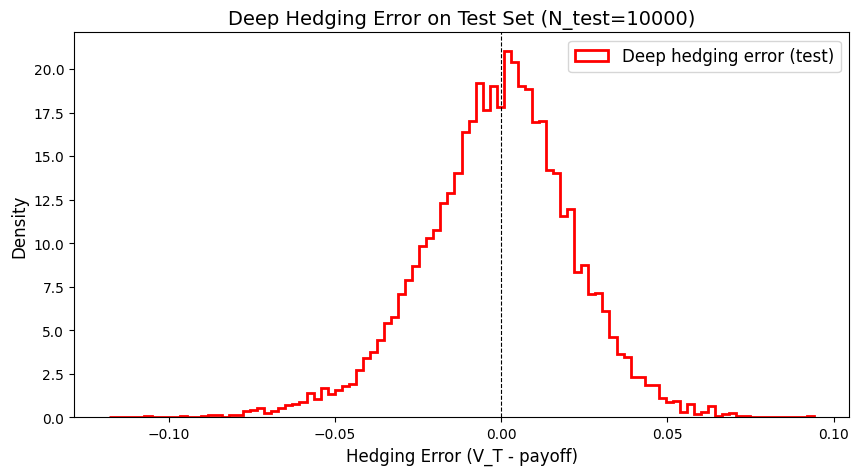

In [14]:
# Histogram on test set
bins = int(np.sqrt(N_test))

plt.figure(figsize=(10, 5))
plt.hist(hedging_error_test, bins=bins, density=True, histtype='step',
         linewidth=2, color='red', label='Deep hedging error (test)')
plt.axvline(0, color='k', linestyle='--', linewidth=0.8)
plt.xlabel('Hedging Error (V_T - payoff)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title(f'Deep Hedging Error on Test Set (N_test={N_test})', fontsize=14)
plt.legend(fontsize=12)
plt.show()

The test-set error distribution is similar to the training distribution for independently generated paths under the same stochastic assumptions. This assesses out-of-sample behavior within the simulated model, not robustness to changes in market dynamics.

### 5.3 Delta Profiles

We evaluate the learned delta functions $\delta^1(t_j, S^1, S^2)$ and $\delta^2(t_j, S^1, S^2)$ over a grid.

Since the deltas are functions of two variables, we fix one asset at $S_0$ and vary the other.

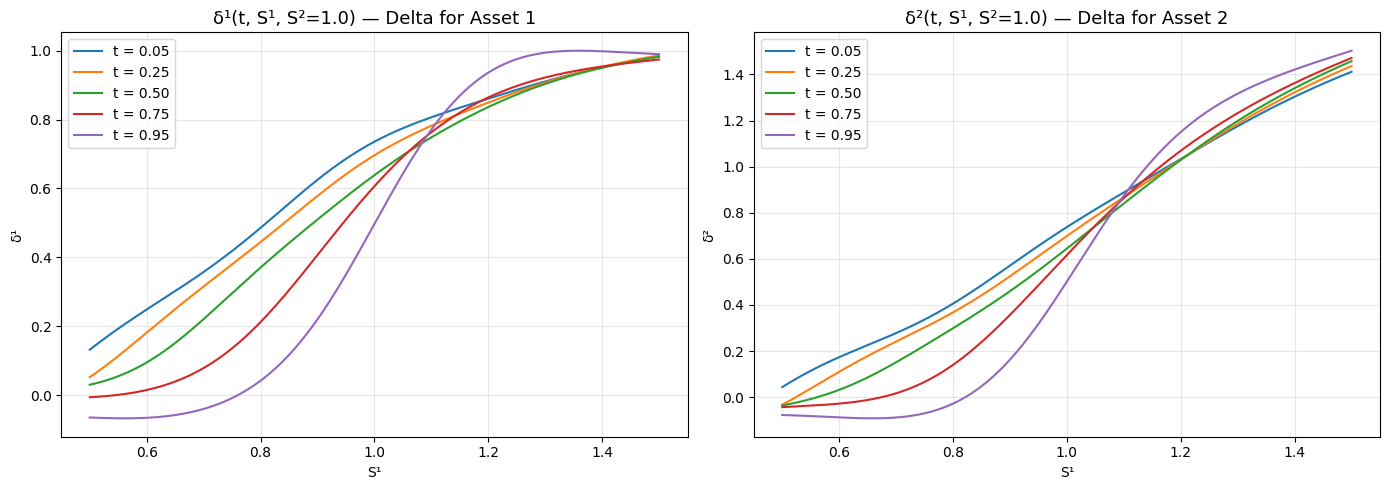

In [15]:
# Build a separate model that outputs the deltas at each time step
# We'll do this by direct forward-pass evaluation using the trained layers

def evaluate_deltas_at_time(j, S1_grid, S2_grid):
    t_val = np.full_like(S1_grid, grid[j]/T)

    x = np.column_stack([t_val, S1_grid, S2_grid]).astype(np.float32)
    x = tf.constant(x)

    for k in range(d):
        x = layers[k](x)

    deltas = x.numpy()
    return deltas[:, 0], deltas[:, 1]

# Create evaluation grid: vary S1 while fixing S2 = S0_2
n_grid = 200
S1_eval = np.linspace(0.5, 1.5, n_grid)
S2_fixed = S0_2 * np.ones(n_grid)

time_indices = [5, 25, 50, 75, 95]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for l in time_indices:
    d1, d2 = evaluate_deltas_at_time(l, S1_eval, S2_fixed)
    axes[0].plot(S1_eval, d1, label=f't = {grid[l]:.2f}')
    axes[1].plot(S1_eval, d2, label=f't = {grid[l]:.2f}')

axes[0].set_title('δ¹(t, S¹, S²=1.0) — Delta for Asset 1', fontsize=13)
axes[0].set_xlabel('S¹')
axes[0].set_ylabel('δ¹')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('δ²(t, S¹, S²=1.0) — Delta for Asset 2', fontsize=13)
axes[1].set_xlabel('S¹')
axes[1].set_ylabel('δ²')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

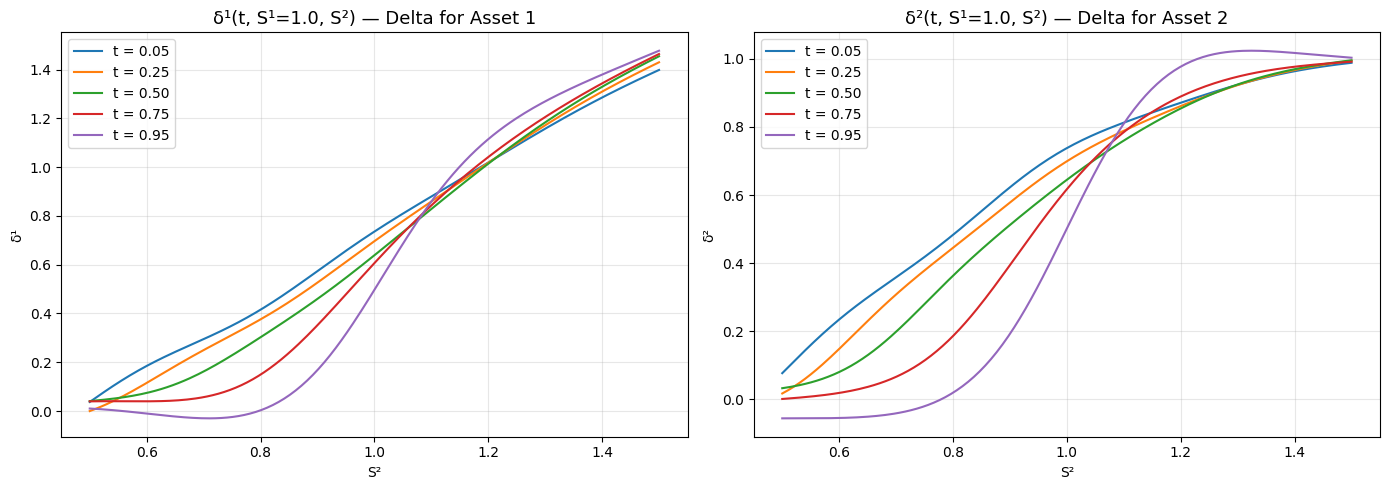

In [16]:
# Now vary S2 while fixing S1 = S0_1
S1_fixed = S0_1 * np.ones(n_grid)
S2_eval = np.linspace(0.5, 1.5, n_grid)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for l in time_indices:
    d1, d2 = evaluate_deltas_at_time(l, S1_fixed, S2_eval)
    axes[0].plot(S2_eval, d1, label=f't = {grid[l]:.2f}')
    axes[1].plot(S2_eval, d2, label=f't = {grid[l]:.2f}')

axes[0].set_title('δ¹(t, S¹=1.0, S²) — Delta for Asset 1', fontsize=13)
axes[0].set_xlabel('S²')
axes[0].set_ylabel('δ¹')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('δ²(t, S¹=1.0, S²) — Delta for Asset 2', fontsize=13)
axes[1].set_xlabel('S²')
axes[1].set_ylabel('δ²')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The learned deltas are globally consistent with financial intuition and correctly capture time dependence and cross-asset structure, but remain too smooth and slightly biased in low-price regions, reflecting approximation limits of the neural network.

### 5.4 Delta Surface (3D) at a fixed time

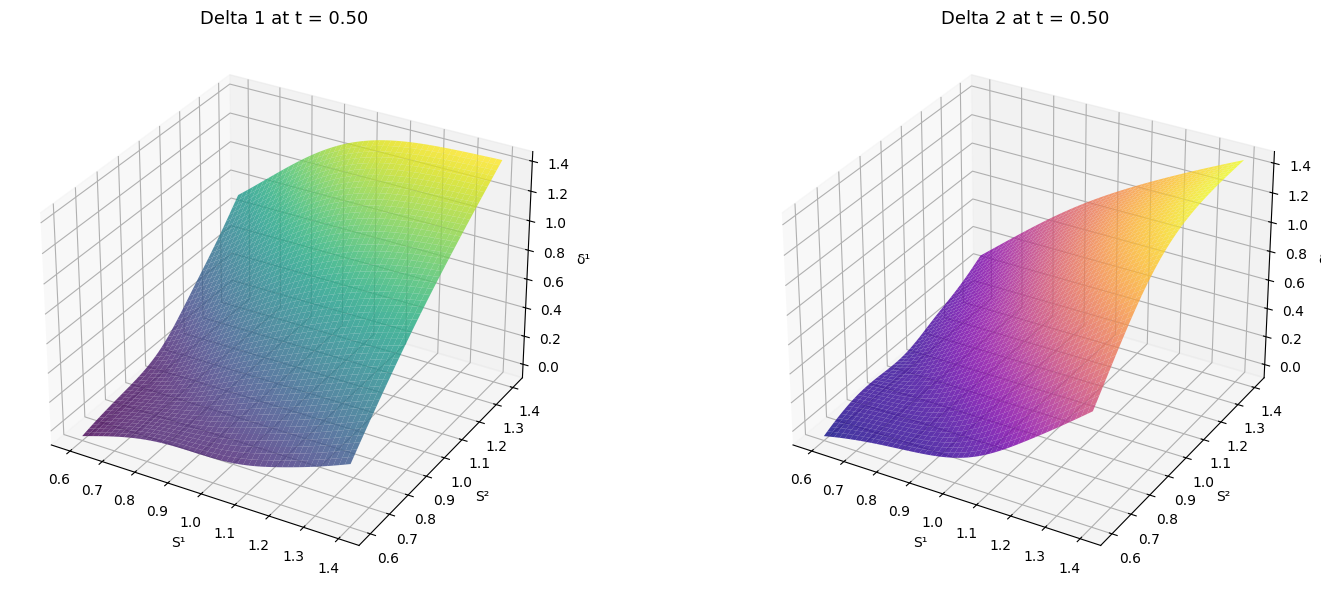

In [17]:
from mpl_toolkits.mplot3d import Axes3D

# 3D surface plot of delta1 and delta2 at a chosen time
t_idx = 50  # mid-way through

n_surf = 50
S1_range = np.linspace(0.6, 1.4, n_surf)
S2_range = np.linspace(0.6, 1.4, n_surf)
S1_mesh, S2_mesh = np.meshgrid(S1_range, S2_range)

S1_flat = S1_mesh.flatten()
S2_flat = S2_mesh.flatten()

d1_flat, d2_flat = evaluate_deltas_at_time(t_idx, S1_flat, S2_flat)
D1_mesh = d1_flat.reshape(n_surf, n_surf)
D2_mesh = d2_flat.reshape(n_surf, n_surf)

fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(S1_mesh, S2_mesh, D1_mesh, cmap='viridis', alpha=0.8)
ax1.set_xlabel('S¹')
ax1.set_ylabel('S²')
ax1.set_zlabel('δ¹')
ax1.set_title(f'Delta 1 at t = {grid[t_idx]:.2f}', fontsize=13)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(S1_mesh, S2_mesh, D2_mesh, cmap='plasma', alpha=0.8)
ax2.set_xlabel('S¹')
ax2.set_ylabel('S²')
ax2.set_zlabel('δ²')
ax2.set_title(f'Delta 2 at t = {grid[t_idx]:.2f}', fontsize=13)

plt.tight_layout()
plt.show()

The delta surfaces are smooth, increasing in both assets, and reflect the joint dependence of the payoff, indicating that the model has learned a consistent and economically meaningful 2D hedging strategy.


### 5.5 Monte Carlo reference price

We estimate a reference option price by simulating the two assets under risk-neutral dynamics and discounting the resulting payoffs. Under the assumed correlated geometric Brownian motions, the terminal product is itself lognormal, so an analytical valuation is also available; the Monte Carlo benchmark provides a direct numerical comparison.

In [18]:
# Monte Carlo pricing under risk-neutral dynamics
N_mc = 500000
np.random.seed(999)

# Under risk-neutral measure: mu_k -> r - 0.5 * sigma_k^2 for the log-drift over the whole period T
# But it's simpler to just simulate with drift r
G_mc = np.random.multivariate_normal(mean=[0, 0], cov=cov_matrix, size=N_mc)

log_S1_T = np.log(S0_1) + (r - 0.5 * sigma1**2) * T + sigma1 * np.sqrt(T) * G_mc[:, 0]
log_S2_T = np.log(S0_2) + (r - 0.5 * sigma2**2) * T + sigma2 * np.sqrt(T) * G_mc[:, 1]

S1_T_mc = np.exp(log_S1_T)
S2_T_mc = np.exp(log_S2_T)

payoff_mc = np.maximum(S1_T_mc * S2_T_mc / (S0_1 * S0_2) - 1.0, 0.0)
mc_price = np.exp(-r * T) * np.mean(payoff_mc)
mc_std = np.exp(-r * T) * np.std(payoff_mc) / np.sqrt(N_mc)

print(f"Monte Carlo option price (risk-neutral): {mc_price:.4f} ± {mc_std:.4f}")
print(f"Deep hedging learned premium:             {learned_premium:.4f}")

Monte Carlo option price (risk-neutral): 0.2454 ± 0.0006
Deep hedging learned premium:             0.2439


### 5.6 Summary statistics table

In [19]:
print("=" * 55)
print("  DEEP HEDGING RESULTS — 2D PROBLEM")
print("=" * 55)
print(f"\n  Option: ATM call on product S1*S2/(S0_1*S0_2)")
print(f"  Parameters: σ1={sigma1}, σ2={sigma2}, ρ={rho}, r={r}")
print(f"  N={N} time steps, T={T} year")
print(f"\n  MC reference price:    {mc_price:.4f}")
print(f"  Deep model premium:    {learned_premium:.4f}")
print(f"\n{'':30s} {'Train':>12s} {'Test':>12s}")
print("-" * 55)
print(f"{'Mean hedging error':30s} {np.mean(hedging_error):12.4e} {np.mean(hedging_error_test):12.4e}")
print(f"{'Std dev hedging error':30s} {np.std(hedging_error):12.4e} {np.std(hedging_error_test):12.4e}")
print(f"{'MSE':30s} {np.mean(hedging_error**2):12.4e} {np.mean(hedging_error_test**2):12.4e}")
print(f"{'5th percentile':30s} {np.percentile(hedging_error, 5):12.4e} {np.percentile(hedging_error_test, 5):12.4e}")
print(f"{'95th percentile':30s} {np.percentile(hedging_error, 95):12.4e} {np.percentile(hedging_error_test, 95):12.4e}")

  DEEP HEDGING RESULTS — 2D PROBLEM

  Option: ATM call on product S1*S2/(S0_1*S0_2)
  Parameters: σ1=0.22, σ2=0.3, ρ=0.5, r=0.04
  N=100 time steps, T=1.0 year

  MC reference price:    0.2454
  Deep model premium:    0.2439

                                      Train         Test
-------------------------------------------------------
Mean hedging error              -1.4096e-03  -1.2580e-03
Std dev hedging error            2.2436e-02   2.2580e-02
MSE                              5.0537e-04   5.1144e-04
5th percentile                  -3.9980e-02  -3.9119e-02
95th percentile                  3.3321e-02   3.3503e-02


The learned initial premium is close to the Monte Carlo reference price, while the independently generated test paths produce a hedging-error distribution similar to the training paths. These results indicate that the shared-network strategy captures the joint dependence of the two assets under the chosen lognormal dynamics. Residual error remains due to discrete rebalancing and finite model capacity; transaction costs and model misspecification are outside the scope of this experiment.